# 10 — Four-Model Comparison (LIVE artifacts, no hardcoded model metrics)

All model metrics are read **directly from saved experiment artifacts** on Google Drive. No training, no GPU required. The YOLO and RT-DETR tuning outputs were produced on Kaggle; upload/copy their exported ZIPs to your Google Drive first. Comparing folds requires exactly 3 video-disjoint folds, the same `COCOeval` settings and metrics.

**Data inputs:** `faster_rcnn` + `faster_rcnn_tuning` CSVs, `retinanet_v2_baseline` + `retinanet_v2_tuning` CSVs, `yolo_tuning_results.zip` (`coco_metrics.json`), `rtdetr_tuning_essentials.zip` (`coco_metrics.json`). **No weights (`.pt`) needed for metrics comparison.**


## 1. Mount Google Drive (Colab)
Copy the two exported Kaggle ZIP files to `MyDrive/UCU_AI_HW2/` or any subdirectory of that folder. The code auto-discovers matching ZIPs. If they have different names, change `YOLO_ZIP` and `RTDETR_ZIP` in the next cell.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import json, zipfile, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=Path('/content/drive/MyDrive/UCU_AI_HW2')
assert ROOT.is_dir(), f'Missing Google Drive folder: {ROOT}'
OUT=ROOT/'four_model_comparison_live'
OUT.mkdir(parents=True,exist_ok=True)

def search_file(pattern):
    matches=sorted(ROOT.rglob(pattern))
    if matches:
        print(f'{pattern}: {len(matches)} match(es):',*[str(p) for p in matches],sep='\n  ')
    else:
        print(f'{pattern}: NOT FOUND')
    return matches

print('Drive root:',ROOT)
search_file('yolo_tuning_results.zip')
search_file('rtdetr_tuning_essentials.zip')

Mounted at /content/drive
Drive root: /content/drive/MyDrive/UCU_AI_HW2
yolo_tuning_results.zip: 1 match(es):
  /content/drive/MyDrive/UCU_AI_HW2/yolo_tuning_results.zip
rtdetr_tuning_essentials.zip: 1 match(es):
  /content/drive/MyDrive/UCU_AI_HW2/rtdetr_tuning_essentials.zip


[PosixPath('/content/drive/MyDrive/UCU_AI_HW2/rtdetr_tuning_essentials.zip')]

## 2. Set input paths
These are **paths to your real artifacts**, not hardcoded results. If a ZIP is not found, upload it to the Drive folder and rerun the previous cell. When different ZIP versions exist, set an exact path instead of auto-discovery.

In [2]:
YOLO_ZIP = None     # e.g. ROOT/'yolo_tuning_results.zip'
RTDETR_ZIP = None   # e.g. ROOT/'rtdetr_tuning_essentials.zip'

def choose_zip(explicit, pattern):
    if explicit is not None:
        p=Path(explicit)
        assert p.is_file() and zipfile.is_zipfile(p), p
        return p
    matches=[p for p in ROOT.rglob(pattern) if zipfile.is_zipfile(p)]
    assert len(matches)==1, f'Expected one {pattern}, got {len(matches)}; set path manually: {matches}'
    return matches[0]

YOLO_ZIP=choose_zip(YOLO_ZIP,'yolo_tuning_results.zip')
RTDETR_ZIP=choose_zip(RTDETR_ZIP,'rtdetr_tuning_essentials.zip')
print('YOLO metrics ZIP:',YOLO_ZIP)
print('RT-DETR metrics ZIP:',RTDETR_ZIP)

YOLO metrics ZIP: /content/drive/MyDrive/UCU_AI_HW2/yolo_tuning_results.zip
RT-DETR metrics ZIP: /content/drive/MyDrive/UCU_AI_HW2/rtdetr_tuning_essentials.zip


## 3. Load exact metrics from each source
CSV files are read from Colab Drive; JSON results are read **directly from the ZIP members, without extraction or retraining**. Each row is identified by `architecture, configuration, fold` and source path.


In [3]:
METRICS = ['mAP50-95','AP50','AP75','AP_small','AP_medium','AP_large']
ROWS=[]
def append_record(arch,config,fold,vals,source):
    rec={'architecture':arch,'configuration':config,'fold':int(fold),'source':str(source)}
    aliases={'mAP50-95':['mAP50-95','map50_95'],
             'AP50':['AP50','mAP50'], 'AP75':['AP75','mAP75'],
             'AP_small':['AP_small'], 'AP_medium':['AP_medium'], 'AP_large':['AP_large']}
    for dest, candidates in aliases.items():
        rec[dest]=next((float(vals[k]) for k in candidates if k in vals and pd.notna(vals[k])),np.nan)
    assert 0 <= rec['mAP50-95'] <= 1, (arch,config,fold,rec)
    ROWS.append(rec)

def read_csv_folds(arch,config,root):
    root=Path(root)
    for fold in (0,1,2):
        f=root/f'fold_{fold}'/'validation_metrics.csv'
        assert f.is_file(), f'Missing {arch}/{config} fold {fold}: {f}'
        df=pd.read_csv(f)
        assert len(df)==1 and int(df.iloc[0]['fold'])==fold, f
        append_record(arch,config,fold,df.iloc[0].to_dict(),f)

# Faster R-CNN: paths from the completed Colab notebooks
read_csv_folds('Faster R-CNN','baseline 640',ROOT/'faster_rcnn')
# Its tuned fold 0 and folds 1-2 use different folders:
for f in (0,1,2):
    p=(ROOT/'faster_rcnn_tuning'/'resolution_768'/'validation_metrics.csv' if f==0
       else ROOT/'faster_rcnn_tuning'/'resolution_768_3fold'/f'fold_{f}'/'validation_metrics.csv')
    if not p.is_file():
        alternatives=list((ROOT/'faster_rcnn_tuning').rglob('validation_metrics.csv'))
        raise FileNotFoundError(f'Cannot locate Faster R-CNN tuned fold {f}: {p}\nFound: {alternatives}')
    x=pd.read_csv(p);assert len(x)==1
    append_record('Faster R-CNN','tuned 768',f,x.iloc[0].to_dict(),p)

# RetinaNet: exact saved metrics
read_csv_folds('RetinaNet','baseline 640',ROOT/'retinanet_v2_baseline')
read_csv_folds('RetinaNet','tuned 768',ROOT/'retinanet_v2_tuning'/'resolution_768')
read_csv_folds('RetinaNet','focal gamma 1.5',ROOT/'retinanet_v2_tuning'/'focal_gamma_1p5')

print('Loaded exact Colab CSV rows:',len(ROWS))

Loaded exact Colab CSV rows: 15


In [4]:
def load_zip_json(zippath):
    with zipfile.ZipFile(zippath) as z:
        members=[m for m in z.namelist() if m.endswith('/coco_metrics.json')]
        assert members, f'No coco_metrics.json found in {zippath}'
        return [(m,json.loads(z.read(m))) for m in members]

# YOLO tagging from 05_YOLO_Tuning; include only exact 3-fold configurations
YOLO_MAP={
    's960_adamw_lr0005':'YOLO11s 960 AdamW LR5e-4',
}
for member, m in load_zip_json(YOLO_ZIP):
    tag=str(m.get('tag',''))
    if tag in YOLO_MAP:
        append_record('YOLO11',YOLO_MAP[tag],m['fold'],m,f'{YOLO_ZIP}::{member}')
    elif tag.startswith('baseline_yolo11n_fold'):
        append_record('YOLO11','YOLO11n baseline 640',m['fold'],m,f'{YOLO_ZIP}::{member}')

# RT-DETR tagging from 08_RTDETR_Tuning; historical eval was saved in same OUT
RT_MAP={'_baseline_external':'baseline LR1e-4','lr2e4':'tuned LR2e-4','lr5e5':'LR5e-5'}
for member,m in load_zip_json(RTDETR_ZIP):
    tag=str(m.get('trial',''))
    if tag in RT_MAP:
        append_record('RT-DETR-L',RT_MAP[tag],m['fold'],m,f'{RTDETR_ZIP}::{member}')

raw=pd.DataFrame(ROWS)
assert not raw.empty
assert not raw.duplicated(['architecture','configuration','fold']).any(), 'Duplicate metric rows: check ZIP contents'
raw=raw.sort_values(['architecture','configuration','fold']).reset_index(drop=True)
raw.to_csv(OUT/'all_models_exact_per_fold.csv',index=False)
display(raw[['architecture','configuration','fold','mAP50-95','AP50','AP_small']].round(5))
print('Rows:',len(raw), '| ZIP metric JSONs are original experiment records.')

,architecture,configuration,fold,mAP50-95,AP50,AP_small
0,Faster R-CNN,baseline 640,0,0.15414,0.30393,0.04823
1,Faster R-CNN,baseline 640,1,0.13896,0.27494,0.03205
2,Faster R-CNN,baseline 640,2,0.14358,0.28507,0.09272
3,Faster R-CNN,tuned 768,0,0.16771,0.33182,0.05612
4,Faster R-CNN,tuned 768,1,0.16238,0.31332,0.03655
5,Faster R-CNN,tuned 768,2,0.17125,0.33612,0.07805
6,RT-DETR-L,LR5e-5,0,0.14118,0.27857,0.05286
7,RT-DETR-L,baseline LR1e-4,0,0.15956,0.31948,0.05952
8,RT-DETR-L,baseline LR1e-4,1,0.15867,0.30750,0.04566
9,RT-DETR-L,baseline LR1e-4,2,0.14927,0.28955,0.07407


Rows: 25 | ZIP metric JSONs are original experiment records.


## 4. Validate comparability and rank complete configurations
**No model is given a fake fold.** A model configuration qualifies for the mean comparison only when it has folds 0, 1 and 2. Fold-based model selection is not an independent test; the original holdout is kept separate.


In [5]:
full=[]
for (arch,config),g in raw.groupby(['architecture','configuration']):
    f=sorted(g['fold'].tolist())
    print(f'{arch} / {config}: folds {f}')
    if f==[0,1,2]:
        full.append(g)
assert full,'No complete three-fold configuration found.'
complete=pd.concat(full,ignore_index=True)
summary=(complete.groupby(['architecture','configuration']).agg(
  mean_mAP=('mAP50-95','mean'), std_mAP=('mAP50-95','std'),
  mean_AP50=('AP50','mean'), mean_AP_small=('AP_small','mean'))
  .reset_index().sort_values('mean_mAP',ascending=False))
display(summary.round(5))
summary.to_csv(OUT/'exact_threefold_comparison.csv',index=False)
best=(summary.sort_values('mean_mAP',ascending=False).groupby('architecture',as_index=False).head(1).sort_values('mean_mAP',ascending=False))
print('BEST VERIFIED CONFIGURATION PER ARCHITECTURE')
display(best.round(5))
best.to_csv(OUT/'best_per_architecture.csv',index=False)

Faster R-CNN / baseline 640: folds [0, 1, 2]
Faster R-CNN / tuned 768: folds [0, 1, 2]
RT-DETR-L / LR5e-5: folds [0]
RT-DETR-L / baseline LR1e-4: folds [0, 1, 2]
RT-DETR-L / tuned LR2e-4: folds [0, 1, 2]
RetinaNet / baseline 640: folds [0, 1, 2]
RetinaNet / focal gamma 1.5: folds [0, 1, 2]
RetinaNet / tuned 768: folds [0, 1, 2]
YOLO11 / YOLO11s 960 AdamW LR5e-4: folds [0, 1, 2]


,architecture,configuration,mean_mAP,std_mAP,mean_AP50,mean_AP_small
7,YOLO11,YOLO11s 960 AdamW LR5e-4,0.17439,0.00816,0.32982,0.06346
6,RetinaNet,tuned 768,0.16989,0.01031,0.32123,0.04775
1,Faster R-CNN,tuned 768,0.16712,0.00446,0.32709,0.05691
2,RT-DETR-L,baseline LR1e-4,0.15583,0.00570,0.30551,0.05975
3,RT-DETR-L,tuned LR2e-4,0.15252,0.00647,0.30284,0.05786
5,RetinaNet,focal gamma 1.5,0.15163,0.01118,0.28875,0.03277
4,RetinaNet,baseline 640,0.14976,0.00928,0.28535,0.03210
0,Faster R-CNN,baseline 640,0.14556,0.00778,0.28798,0.05767


BEST VERIFIED CONFIGURATION PER ARCHITECTURE


,architecture,configuration,mean_mAP,std_mAP,mean_AP50,mean_AP_small
7,YOLO11,YOLO11s 960 AdamW LR5e-4,0.17439,0.00816,0.32982,0.06346
6,RetinaNet,tuned 768,0.16989,0.01031,0.32123,0.04775
1,Faster R-CNN,tuned 768,0.16712,0.00446,0.32709,0.05691
2,RT-DETR-L,baseline LR1e-4,0.15583,0.00570,0.30551,0.05975


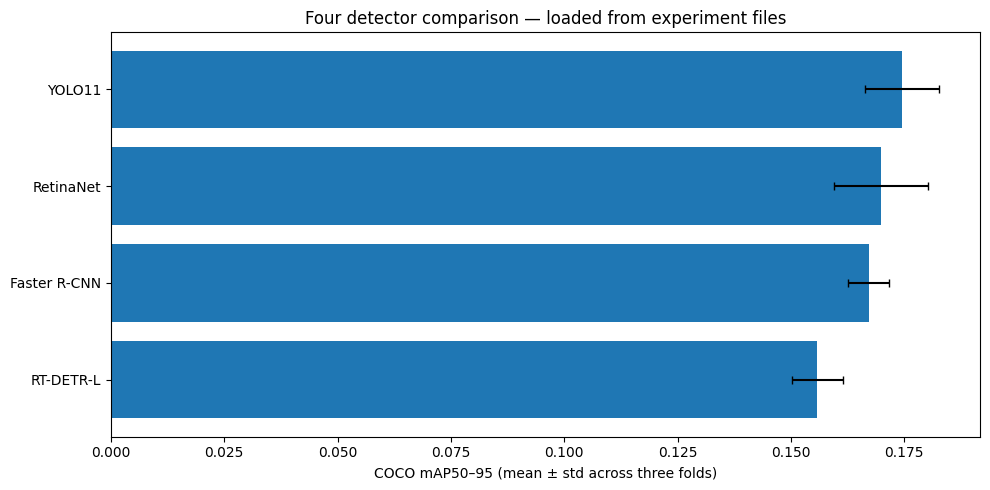

PROVISIONAL top 2 for final training (CV only):


,architecture,configuration,mean_mAP,mean_AP_small
7,YOLO11,YOLO11s 960 AdamW LR5e-4,0.17439,0.06346
6,RetinaNet,tuned 768,0.16989,0.04775


In [6]:
fig,ax=plt.subplots(figsize=(10,5))
d=best.sort_values('mean_mAP')
ax.barh(d.architecture,d.mean_mAP,xerr=d.std_mAP,capsize=3)
ax.set_xlabel('COCO mAP50–95 (mean ± std across three folds)')
ax.set_title('Four detector comparison — loaded from experiment files')
plt.tight_layout();plt.savefig(OUT/'four_detector_comparison.png',dpi=180);plt.show()

print('PROVISIONAL top 2 for final training (CV only):')
display(best.head(2)[['architecture','configuration','mean_mAP','mean_AP_small']].round(5))

## 5. Leaderboard is **not** the three-fold metric

Existing YOLO11s **18-epoch** experiment achieved a **public Kaggle leaderboard score of 0.18731**, while the earlier attempt scored **0.17610** and the organizer baseline is **0.22163**. These are historical leaderboard observations, **not read from CV metrics**, and they must not be compared arithmetically with three-fold COCO mAP.

Choosing **6 epochs** for final experiments is a deliberate compute-budget constraint. Train from pretrained weights on all permitted **train** sequences, evaluate on held-out validation videos and inspect overfitting/underfitting. Six epochs may underfit; 18 epochs do **not** establish overfitting without a train-versus-validation trajectory. Keep the existing 18-epoch model as a separate candidate rather than discarding its demonstrated Kaggle score.

## 6. Save results / do not launch training from this notebook

Use a separate notebook for each selected final model. Preserve training-validation isolation and export a `submission.csv` for each. Keep exact source CSVs/JSONs accessible for the report and defense. This comparison notebook deliberately runs on **CPU only**.

In [7]:
from zipfile import ZipFile,ZIP_DEFLATED
archive=OUT/'four_model_comparison_exact_results.zip'
with ZipFile(archive,'w',ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        if f.is_file() and f!=archive:
            z.write(f,arcname=f.name)
print('Saved',archive,'size MB:',round(archive.stat().st_size/1e6,2))

Saved /content/drive/MyDrive/UCU_AI_HW2/four_model_comparison_live/four_model_comparison_exact_results.zip size MB: 0.04
